# 12 优惠券使用规则

## 本章范围与资料来源

第 9～11 章完成优惠券管理、领取与领取优化。本章处理领到券之后的交易闭环：定义优惠规则，推荐可叠加的用券方案，计算订单及课程优惠明细，下单核销，取消订单退券，查询历史优惠规则。课件还包含 Caffeine 本地缓存与 Seata 分布式事务练习。

| 来源 | 本章实际使用的内容 |
| --- | --- |
| [网盘分享](https://pan.baidu.com/s/1dcVvDI-sWN68Xzcsz1LSAQ?pwd=w7bj)，提取码 `w7bj` | `day12-优惠券使用规则/讲义/day12-使用优惠券.pptx`，共 41 页；已核对全部页，内嵌第 6、20 页原图 |
| 网盘 `day12-优惠券使用规则/资料` | 确认有 `dto`、`strategy`、`util` 目录；策略目录含 `Discount.java`、`DiscountStrategy.java` 和四个优惠实现类；Java 附件未取得正文，不作为已读源码 |
| [第三方公开转载：Day12-优惠券使用](https://imousse.github.io/cswiki/src/project/college/12-%E4%BC%98%E6%83%A0%E5%88%B8%E4%BD%BF%E7%94%A8) | 补充接口 DTO、查询 SQL、推荐计算、线程池、最优方案筛选、交易下单、核销与退券示例 |

阅读日期：2026-10-09。**课件方案**指课件或讲义明确展示的做法；**整理示例**按材料重写教学片段；**补充 / 改进示例**补足金额、并发、鉴权、幂等与事务边界。Java 示例遵循 Java 11，省略导包和外围类；全部单元为 Markdown。

课件有少量命名和文字沿用问题：PPT 的策略方法写作 `calcDiscount`，公开讲义写作 `calculateDiscount`；PPT 的订单优惠明细页沿用了 `/available`，公开讲义实现为 `/discount`；查询规则页的需求文字沿用了退券描述。本文分别按职责和讲义实现解释，不把这些差异当作新的接口设计。

## 优惠券如何进入订单流程

用户想知道“能省多少”，交易系统还必须回答“每门课分摊多少、券何时不能再用、订单取消后如何恢复”。优惠券使用因此贯穿整个订单生命周期。

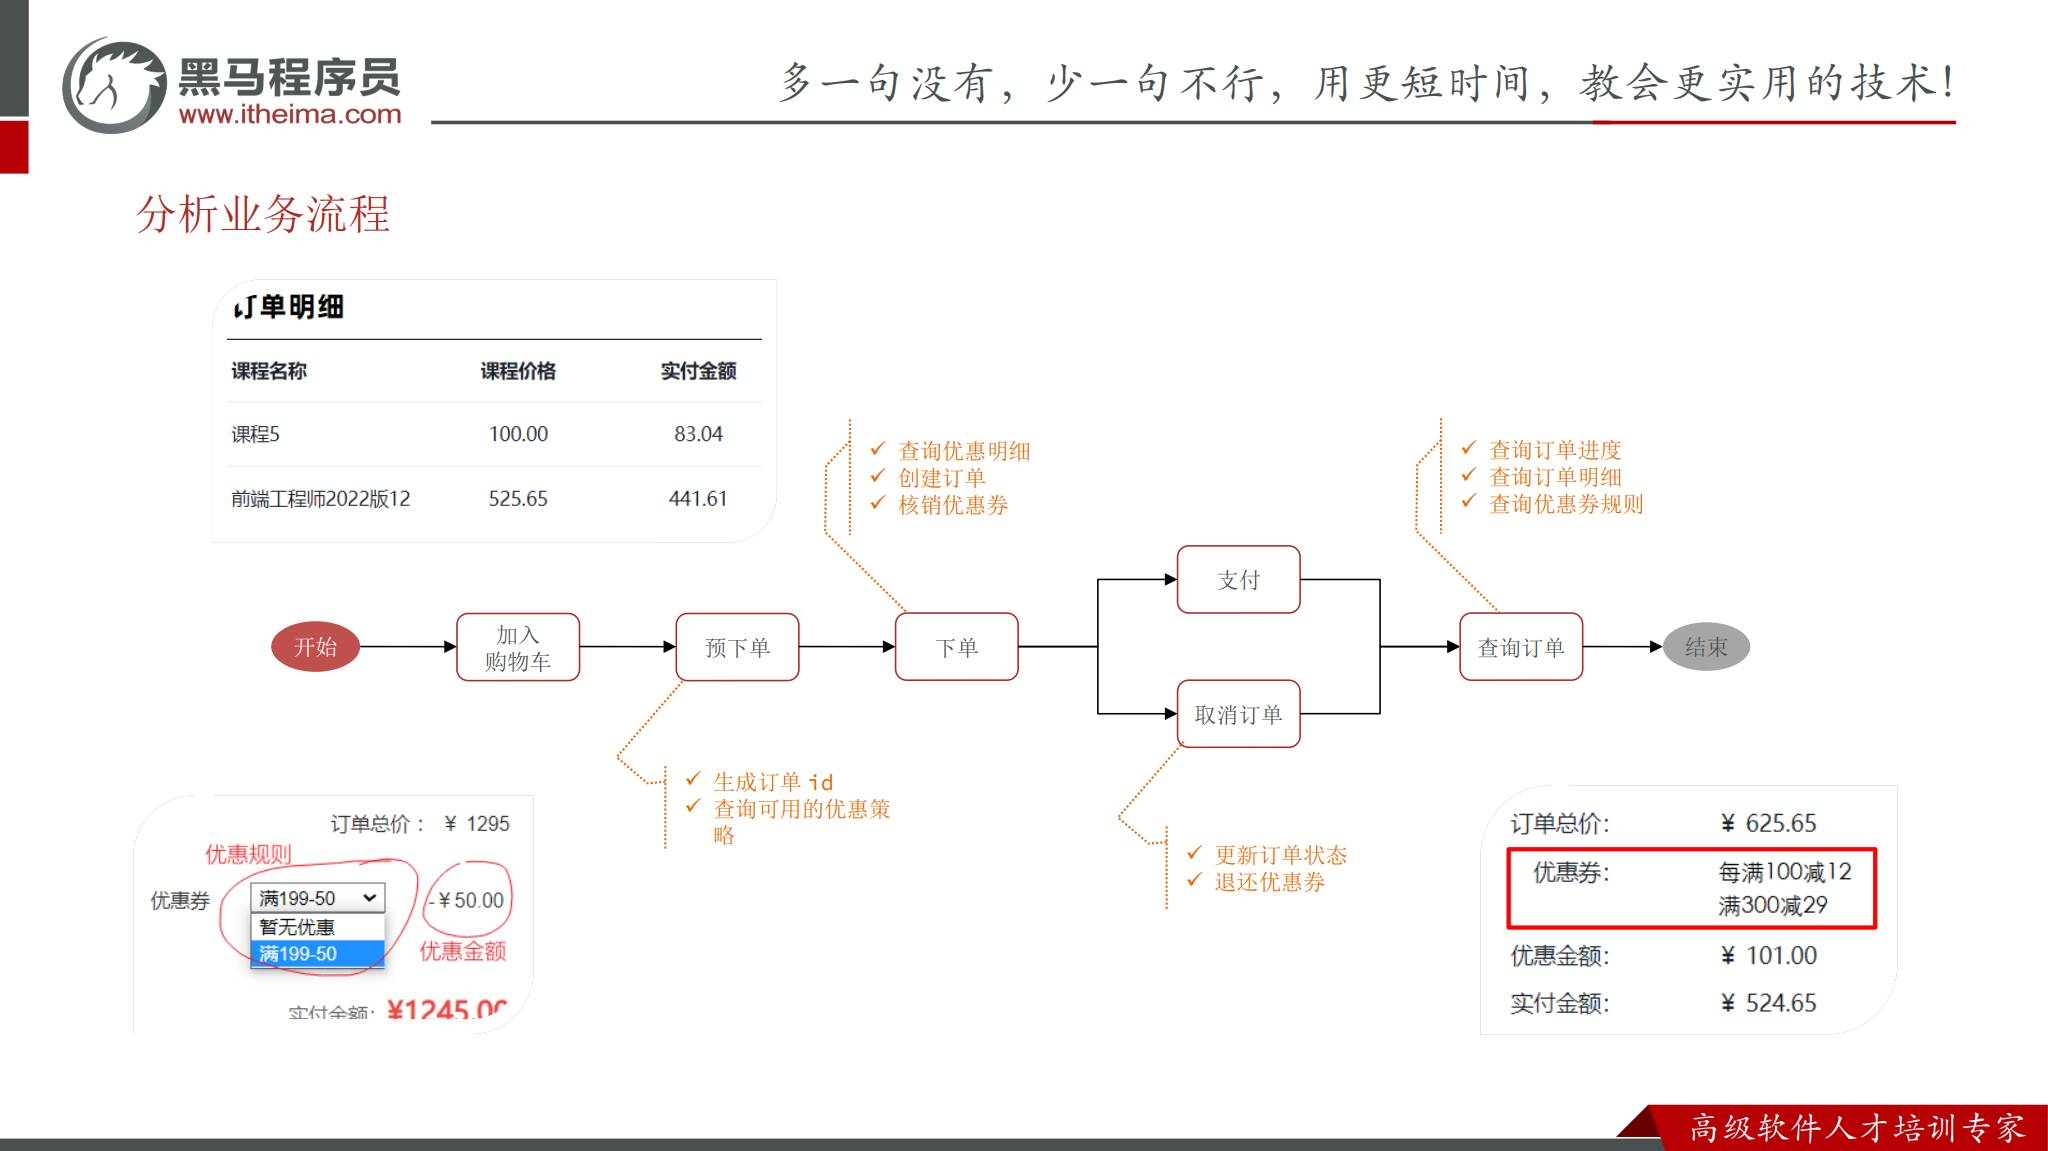

| 阶段 | 交易服务职责 | 优惠券服务职责 |
| --- | --- | --- |
| 预下单 | 查询课程信息、生成订单 ID、组装预览页 | 推荐当前可用的优惠方案 |
| 确认下单 | 重新取价、保存订单和课程明细 | 校验选中的券，计算优惠明细并核销 |
| 支付成功 | 将订单变为已支付，启动后续履约 | 券继续保持已使用 |
| 未支付取消 / 超时关闭 | 将订单变为关闭 | 退还该订单使用的券，已过期的券不能恢复可用 |
| 查询订单 / 退款 | 读取历史价格、优惠和实付 | 提供规则描述；历史展示应读取下单快照 |

预下单推荐是某个时点的报价。它不占用优惠券，也不保证稍后提交时价格、规则和券状态仍然相同。

## 模板、用户券、用券顺序与订单明细

同一模板可以发给很多用户，甚至同一用户持有多张。核销模板 ID 无法确定究竟用了哪张券。

| 对象 | 含义 | 本章用途 |
| --- | --- | --- |
| `coupon.id` | 优惠券模板 ID | 描述优惠类型、门槛、范围，统计使用数量 |
| `user_coupon.id` | 一次领取产生的用户券 ID | 查询归属、有效期、使用状态，执行核销和退还 |
| `CouponDiscountDTO.ids` | 实际参与计算的用户券 ID 序列 | 保留执行顺序，提交和核销必须与其一致 |
| `discountDetail` | 各课程分摊的优惠金额 | 保存订单行实付，支持部分退款 |

`[101, 102]` 与 `[102, 101]` 使用相同两张券，但不一定产生相同金额。比较“用了哪些券”时可以排序生成集合键；真正计算和展示时必须保留原顺序。

本项目用课程 ID 作为明细键，前提是同一订单不会出现重复课程。若业务允许同商品多行，要改用订单行 ID；否则 `Collectors.toMap` 可能抛出重复键异常，或合并时丢失明细。

## 五个接口分别解决什么问题

推荐方案与最终优惠明细属于查询；核销与退券会改变用户券状态。明确职责，才能给不同失败设置正确处理方式。

| 方法与路径 | 请求 | 返回 / 行为 |
| --- | --- | --- |
| `POST /user-coupons/available` | `List<OrderCourseDTO>` | `List<CouponDiscountDTO>`，推荐方案 |
| `POST /user-coupons/discount` | `OrderCouponDTO`：用户券 ID 序列 + 课程列表 | 一组券的优惠总额、规则、课程优惠明细 |
| `PUT /user-coupons/use` | 查询参数 `couponIds`，用户券 ID 集 | 核销优惠券，课件无返回正文 |
| `PUT /user-coupons/refund` | 查询参数 `couponIds`，用户券 ID 集 | 退还优惠券，课件无返回正文 |
| `GET /user-coupons/rules` | 查询参数 `couponIds`，用户券 ID 集 | 规则描述集合 |

课件的核销、退券接口只传券 ID。**补充 / 改进示例**需要传订单 ID 或等价的业务操作标识，才能识别重试和阻止旧订单退还新订单正在使用的券。这是协议与持久化设计扩展，不能仅靠现有参数推断。

## 用策略模式统一优惠规则

满减、每满减、折扣、无门槛券都需要回答三个问题：当前金额能否用、能优惠多少、如何向用户描述。把算法放入各策略，主流程就能统一调用。

**整理示例**：沿用公开讲义的方法名。

```java
public interface Discount {
    boolean canUse(int totalAmount, Coupon coupon);
    int calculateDiscount(int totalAmount, Coupon coupon);
    String getRule(Coupon coupon);
}
```

这里的 `totalAmount` 是**这张券适用课程的当前剩余金额之和**，单位为分。策略只处理金额规则；用户归属、状态、有效期和课程范围由外层校验。

`getRule` 和金额算法使用同一组配置，避免显示“满 200 减 50”却实际减 20。规则文案要说明范围、封顶和叠加条件。

**面试提示**：策略模式封装可替换算法；工厂负责选择算法；校验流程负责业务资格。三者职责不宜混成一个巨大 `if/else`。

## 四种优惠规则与金额边界

设 `S` 为适用课程剩余金额，`T` 为门槛，`V` 为优惠值，`M` 为可选优惠上限。金额均按整数分存储。

| 策略类 | 规则 | 整理公式 | 示例 |
| --- | --- | --- | --- |
| `NoThresholdDiscount` | 无门槛减固定金额 | `D = min(S, V)` | 30 元商品用减 50 元券，最多减 30 元 |
| `PriceDiscount` | 满减 | `S >= T` 时减 `V` | 满 200 减 25，199 元不能用 |
| `PerPriceDiscount` | 每满减 | `floor(S / T) × V`，再按规则封顶 | 每满 100 减 20，250 元减 40 |
| `RateDiscount` | 满额打折 | 达到门槛后，按约定的比例计算优惠 | 满 300 打 9 折，400 元优惠 40 |

**整理示例**：若约定 `discountValue=90` 表示支付 90%，则优惠比例为 10%；按 `floor(S × (100-90) / 100)` 得到优惠分数。Java 策略附件未读到正文，不能由此断言原附件的折扣编码与舍入方式。

计算后应保证 `0 <= D <= S`；有上限时还要保证 `D <= M`。必须明确数据库中 `M=0` 或空值是否表示“不封顶”。`PerPriceDiscount` 的 `T` 必须大于 0；折扣值、优惠值和门槛在创建模板时校验。

讲义正文曾使用 `maxDiscountValue`，查询 SQL 字段为 `max_discount_amount`。对接代码时以实际实体和表字段为准。

**面试提示**：金额不能直接使用 `double`。整数分解决常见精度问题，但乘法、求和仍可能溢出，要使用 `long` 中间值和明确的舍入规则。

## 工厂选择策略，主流程保持稳定

新增优惠类型时，如果每处调用都维护一份分支，很容易出现推荐支持新规则、下单却不支持的情况。

**课件方案**通过 `DiscountStrategy.getDiscount(DiscountType)` 返回对应实现。**整理示例**省略枚举具体名称，演示注册关系：

```java
private final Map<DiscountType, Discount> strategies = new EnumMap<>(DiscountType.class);

public Discount getDiscount(DiscountType type) {
    Discount strategy = strategies.get(type);
    if (strategy == null) {
        throw new IllegalArgumentException("不支持的优惠类型");
    }
    return strategy;
}
```

初始化时注册四种实现；配置完整后只读。策略保持无状态，把本次金额和券配置作为参数传入，多个计算任务就能安全共用策略对象。

未知类型应明确失败。推荐可以淘汰配置无效的候选并记录原因，最终下单不能悄悄把未知规则当成零优惠。

## 推荐方案的六步计算链路

用户持有的券不一定适用于本次订单，适用的券也不一定能一起满足门槛。先缩小候选，再计算方案，才能减少无效工作。

```text
查询当前用户未使用的券
  → 按订单总价初筛
  → 按限定分类筛出每张券的适用课程
  → 枚举不同用券顺序与单券方案
  → 逐券计算、分摊到课程（不同方案可并行）
  → 按相同券集 / 相同金额筛选结果
```

**课件方案**在 `UserCouponController` 提供入口，在 `IDiscountService` / `DiscountServiceImpl` 实现推荐。交易服务预下单接口 `/ts/orders` 查询课程数据后调用优惠券服务。

单个方案内有金额依赖，必须顺序执行；不同方案读取相同输入快照，可以独立并行。查库和鉴权应在提交计算任务之前完成。

## 推荐 DTO 与用户券查询

输入课程既要有价格，又要有三级分类，才能判断金额门槛和限定范围。

| DTO / 字段 | 类型 | 含义 |
| --- | --- | --- |
| `OrderCourseDTO.id` | `Long` | 课程 ID |
| `OrderCourseDTO.price` | `Integer` | 本次下单价格，单位分 |
| `OrderCourseDTO.cateId` | `Long` | 三级分类 ID |
| `CouponDiscountDTO.ids` | `List<Long>` | 实际使用的用户券 ID，保留计算顺序 |
| `CouponDiscountDTO.rules` | `List<String>` | 与用户券序列对应的规则 |
| `CouponDiscountDTO.discountAmount` | `Integer` | 总优惠金额 |

**公开讲义方案**：联表取模板规则，同时取用户券 ID。

```sql
SELECT c.id, c.discount_type, c.specific, c.discount_value,
       c.threshold_amount, c.max_discount_amount,
       uc.id AS creater
FROM user_coupon uc
JOIN coupon c ON uc.coupon_id = c.id
WHERE uc.user_id = #{userId} AND uc.status = 1;
```

这里 `creater` 被临时借用来携带用户券 ID，语义与字段名不一致。**补充 / 改进示例**使用专门的候选 DTO，分别保存 `couponId` 和 `userCouponId`，避免将模板 ID 交给核销接口。

SQL 只检查状态还不够：有效期可能尚未开始，或过期任务尚未修改状态。应读取并检查 `term_begin_time <= now <= term_end_time`，边界包含规则在所有入口保持一致。

## 初筛必须考虑分类范围

订单共 400 元，其中券限定分类只有 100 元，不能按 400 元判断“满 200”。全订单金额只是便宜的第一层筛选。

**课件方案**：先用总价调用 `canUse`，再查询 `coupon_scope`，把符合限定分类的课程与券关联；没有适用课程的券直接淘汰。

| 券范围 | 适用课程集合 | 门槛判断金额 |
| --- | --- | --- |
| 不限定范围 | 订单全部课程 | 全部课程剩余金额之和 |
| 限定三级分类 | `cateId` 命中券范围的课程 | 命中课程剩余金额之和 |

**补充 / 改进示例**：批量读取候选券的范围，整理为 `Map<couponId, Set<cateId>>`，避免每张券各查一次形成 N+1 查询。空范围且标记为限定的配置应视为不可用，不能自动扩大成全范围。

`couponToCoursesMap` 宜用稳定 ID 作为键。可变实体的字段若参与 `equals/hashCode`，修改字段会让 Map 查询失效；独立只读候选对象也更适合并行计算。

## 组合与排列：相同券集也有不同执行顺序

先减 100 元再打 9 折，与先打 9 折再减 100 元，结果可能不同。组合只决定选哪些券；排列还决定以什么顺序执行。

**公开讲义方案**调用 `PermuteUtil.permute(availableCoupons)`，并追加每张券单独使用的方案。

```java
List<List<Coupon>> solutions = PermuteUtil.permute(availableCoupons);
for (Coupon coupon : availableCoupons) {
    solutions.add(List.of(coupon)); // Java 11 支持；列表不可修改
}
```

`PermuteUtil` 附件正文未取得，因此不能断言它是否返回所有长度的排列。若仅返回全长度排列，“全排列 + 单券”没有显式覆盖长度为 `2..n-1` 的有序子集。计算时跳过不满足门槛的券可能偶然产生部分子集，但不能据此保证枚举完整或总能找到用券最少的等价方案。

**补充 / 改进示例**：若产品允许任意非空子集叠加，深度优先遍历每个尚未使用的券，每个非空前缀都是一个候选方案；否则先落实互斥券、最多用券数等产品限制，再按该约束枚举。

**面试提示**：集合键可以排序用于去重，计算序列不能排序；“组合去重”与“按顺序计算”是两个操作。

## 阶乘复杂度先限制搜索，再增加线程

候选券数量稍增，排列数量会急剧上升。线程池只缩短有限并行工作所需的时间，不会降低枚举复杂度。

| 候选券数 `n` | 全长度排列 `n!` | 所有非空有序子集 `Σ n!/(n-k)!` |
| --- | ---: | ---: |
| 3 | 6 | 15 |
| 5 | 120 | 325 |
| 8 | 40,320 | 109,600 |
| 10 | 3,628,800 | 9,864,100 |

**补充 / 改进示例**：设候选数上限、最多叠加张数、任务数上限和总耗时预算；先排除时间或范围不符的券；必要时按已知优惠上界剪枝，避免先生成全部方案占满内存。

限制候选或提前停止搜索后，只能称为“已搜索方案中的最佳推荐”。要宣称全局最优，必须证明枚举完整或剪枝不会遗漏更优解。

面向最终下单只计算用户选择的一组券，无需再次遍历所有排列。

## 一组方案内部按剩余金额逐券计算

前一张券改变后续券的门槛基数。每张券都要重新计算适用课程的剩余金额，不能把最初校验结果一直复用。

**整理示例**：

```text
discountDetail：每门课累计优惠，初始为 0
usedIds / rules：实际使用的券序列，初始为空

按方案顺序遍历每张券：
  取适用课程
  remaining[i] = price[i] - discountDetail[i]
  S = sum(remaining[i])
  若 S 为 0 或不满足门槛：推荐阶段跳过
  D = 策略计算的优惠金额，并校验 0 <= D <= S
  将 D 按 remaining[i] 分摊到课程，累加 discountDetail
  记录该用户券 ID、规则与优惠金额
```

返回总优惠必须等于各课程累计优惠之和，返回券 ID 必须对应实际生效的券。若原方案中一张券未生效，不应把它列为已使用。

推荐阶段允许跳过；最终下单阶段用户指定的券不再满足条件，应返回“优惠已变化，请重新确认”，避免悄悄跳过后按更高金额创建订单。

## 完整示例：顺序为何使优惠从 80 变为 160

**课件示例**：三门课各 100 元，课程 1 属于 a，课程 2、3 属于 b。券 1 为 a、b 每满 100 减 20；券 2 为 b 满 200 减 100；券 3 为 a 满 80 减 20。原课件第 20 页明确券 3 只限 a。

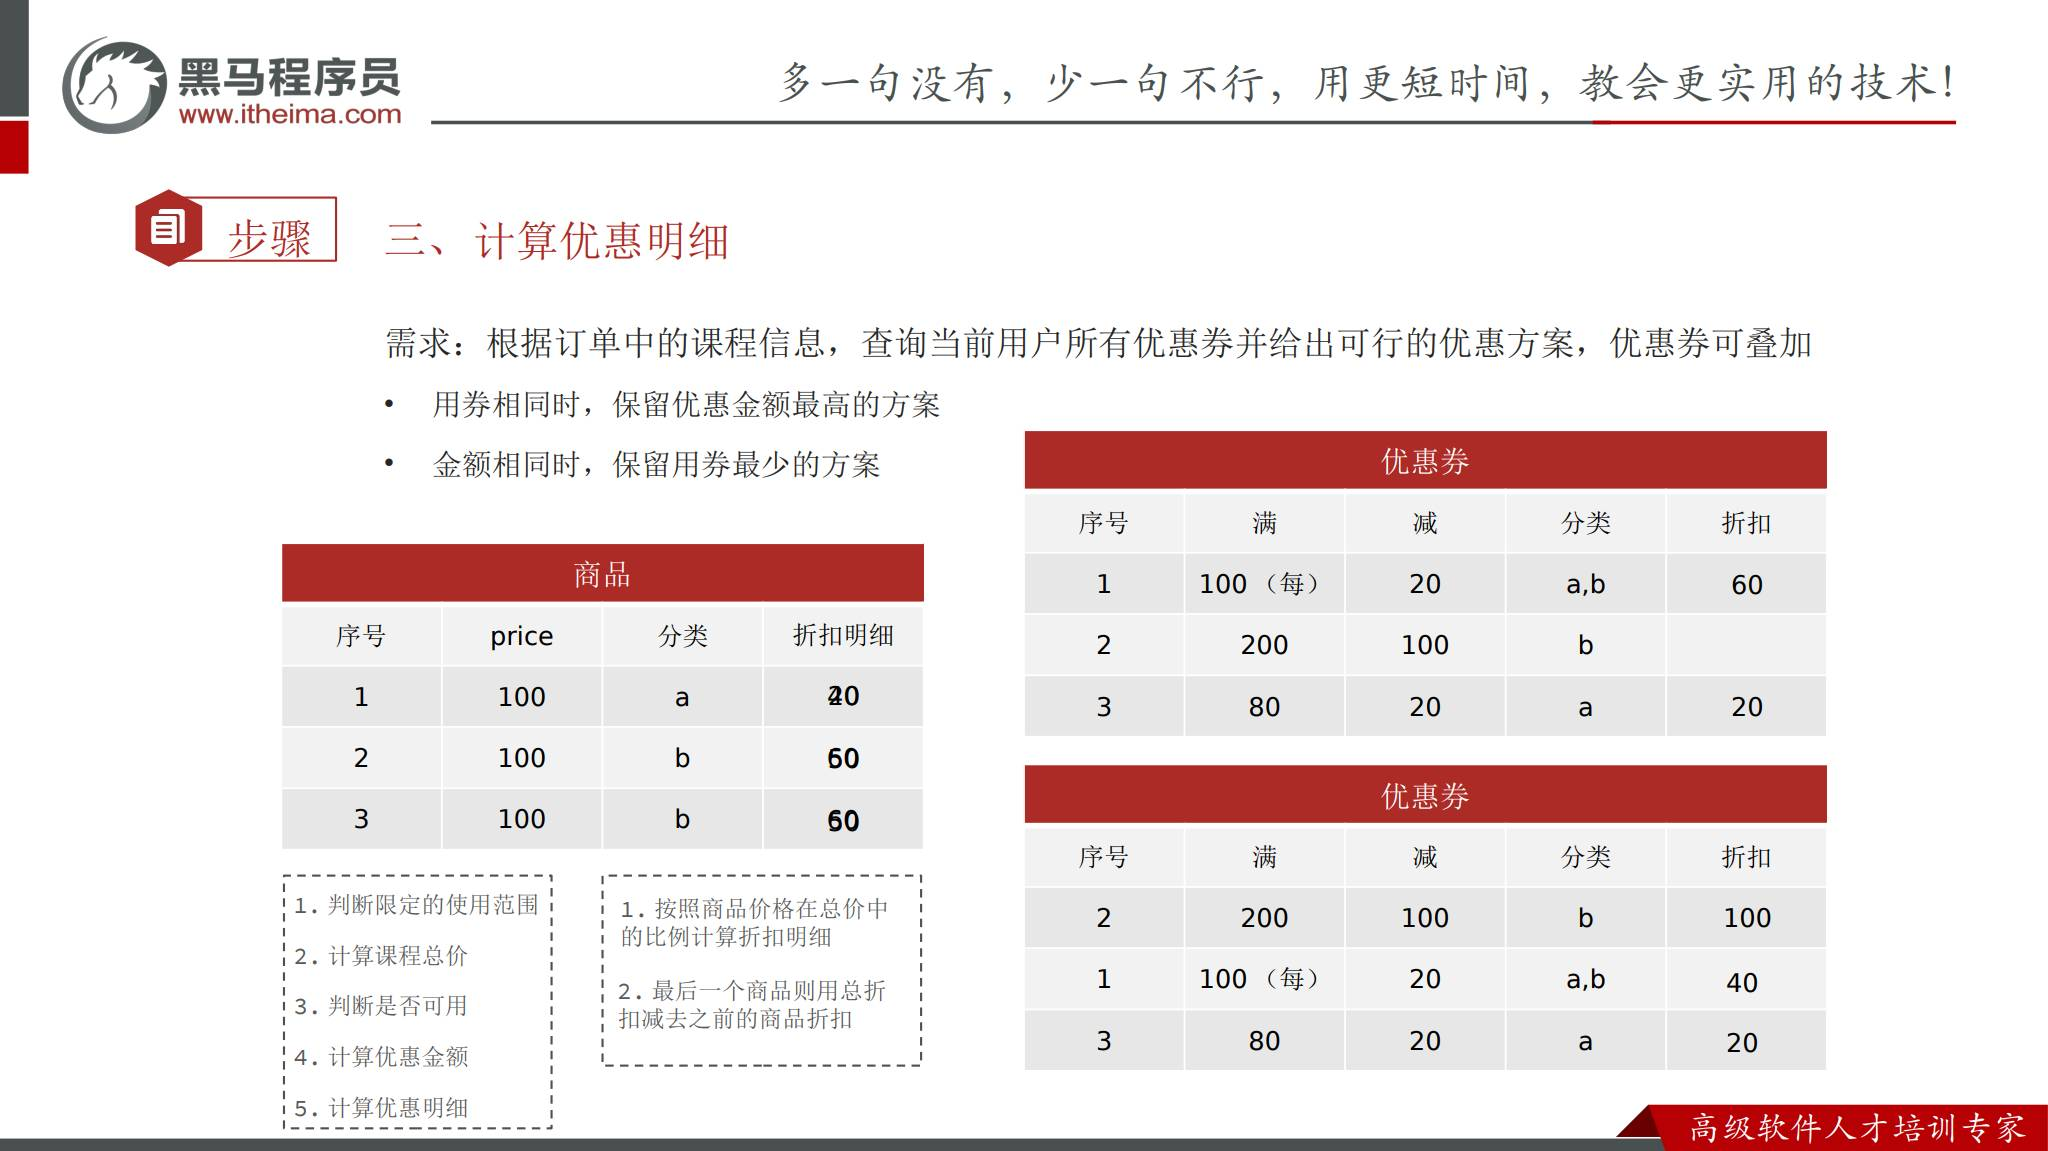

原图保留了 PPT 动画叠加文字，以下表格按“每次以剩余价格分摊”的规则重新计算，金额单位为元。

| 顺序 | 本次门槛基数 | 本次优惠 | 分摊到课程 1 / 2 / 3 | 执行后剩余 1 / 2 / 3 |
| --- | --- | ---: | --- | --- |
| 券 1 → 券 2 → 券 3：券 1 | 300 | 60 | 20 / 20 / 20 | 80 / 80 / 80 |
| 同方案：券 2 | b 分类 160，不满 200 | 0 | 0 / 0 / 0 | 80 / 80 / 80 |
| 同方案：券 3 | a 分类 80 | 20 | 20 / 0 / 0 | 60 / 80 / 80 |
| 券 2 → 券 1 → 券 3：券 2 | b 分类 200 | 100 | 0 / 50 / 50 | 100 / 50 / 50 |
| 同方案：券 1 | 200 | 40 | 20 / 10 / 10 | 80 / 40 / 40 |
| 同方案：券 3 | a 分类 80 | 20 | 20 / 0 / 0 | 60 / 40 / 40 |

第一组实际只用券 1、3，总优惠 80，实付 220；第二组用三张券，总优惠 160，实付 140。这里证明顺序会改变结果，不据两种方案就声称已检查所有最优解。

## 课程优惠分摊：分子与分母要使用同一基数

只保存订单优惠总额，无法正确处理只退其中一门课的情况。优惠必须分摊到订单行，并在下单时持久化。

**公开讲义方案**按比例计算前几门课，最后一门课领取剩余尾差。但示例表达式使用原价作为分子、剩余总价作为分母：

```java
discount = discountAmount * course.getPrice() / totalAmount;
```

已叠加过优惠后，两个基数不一致。以上例第二组券 1 为例：`D=40`、`S=200`，原价均为 100，会分成 `20、20、0`，而剩余金额 `100、50、50` 对应 `20、10、10`。其他金额下甚至可能导致末行分到负数。

**补充 / 改进示例**先算 `remainingPrice = originalPrice - accumulatedDiscount`，再用 `(long) D * remainingPrice / S`。强转必须发生在乘法前；`(long)(D * price)` 无法挽救已经发生的 `int` 溢出。

分摊需要同时满足：每行优惠非负、不超过该行剩余金额、分摊合计恰好等于 `D`。简单把尾差全部给最后一行可能超过小额末行容量，例如剩余 `[1,1,1,1]` 分摊 3 分，前面都向下取整为 0，尾行会拿到 3 分。

## 最大余数法分摊整数分

整数分按比例取整会产生尾差。先给每行分配比例的整数部分，再把剩余的几分钱给小数余数最大的行，可以守住总额和单行上限。

**补充 / 改进示例**：输入是适用课程的剩余分数，课程 / 行 ID 用于同余数时稳定排序；中间乘法用检查溢出的 `long`。该函数适用于每行出现一次的模型。

```java
static Map<Long, Long> allocate(Map<Long, Long> remaining, long discount) {
    long total = 0;
    for (long amount : remaining.values()) {
        if (amount < 0) throw new IllegalArgumentException("剩余金额为负");
        total = Math.addExact(total, amount);
    }
    if (discount < 0 || discount > total) {
        throw new IllegalArgumentException("优惠金额越界");
    }
    Map<Long, Long> result = new HashMap<>();
    Map<Long, Long> remainders = new HashMap<>();
    long allocated = 0;
    for (Map.Entry<Long, Long> entry : remaining.entrySet()) {
        long numerator = Math.multiplyExact(discount, entry.getValue());
        long share = total == 0 ? 0 : numerator / total;
        result.put(entry.getKey(), share);
        remainders.put(entry.getKey(), total == 0 ? 0 : numerator % total);
        allocated = Math.addExact(allocated, share);
    }
    List<Long> ids = new ArrayList<>(remaining.keySet());
    ids.sort(Comparator.<Long>comparingLong(remainders::get)
            .reversed().thenComparingLong(Long::longValue));
    long tail = discount - allocated;
    for (Long id : ids) {
        if (tail == 0) break;
        if (result.get(id) < remaining.get(id)) {
            result.put(id, result.get(id) + 1);
            tail--;
        }
    }
    if (tail != 0) throw new IllegalStateException("尾差未分摊完");
    return result;
}
```

当 `0 <= D <= S` 时，各行精确比例不超过各自剩余金额；不足 1 分的尾差总数小于行数，因此每个符合条件的行至多补 1 分即可。超出约定金额规模时应拒绝请求或使用 `BigInteger`，不能让溢出继续计算。

下单时保存累计优惠和实付：`linePay = originalPrice - lineDiscount`；订单优惠与实付分别等于行优惠与行实付之和。退款沿用这些历史结果。

## 并行任务共享只读输入，各自持有计算状态

多个方案使用相同课程，却有不同累计优惠。共用一张可写的 `discountDetail` 会让一个方案读到另一个方案的折扣。

| 数据 | 共享方式 | 原因 |
| --- | --- | --- |
| 课程价格、分类、券规则、范围 | 提交前构建只读快照 | 避免数据库变更或任务修改影响本次计算 |
| 每组券的累计分摊、实际 ID、总优惠 | 每个任务单独创建 | 不同方案独立计算 |
| 结果 | 每个 Future 返回独立 DTO | 主线程汇总，减少共享集合争用 |
| 用户身份 | 主线程完成鉴权，显式传入必要 ID | `ThreadLocal` 用户上下文不会自动传到线程池 |

`Collections.unmodifiableList` 只禁止列表增删，不会冻结内部对象。快照中的对象也应不可变，或在任务执行期间确保不被修改。

最终结果按明确比较规则排序；不能依赖哪个线程先完成来决定同额方案。

## CompletableFuture 把异步计算表达为结果

`Runnable` 适合只执行动作；推荐需要每组方案的计算结果，因此课件使用 `supplyAsync`。

| 方法 | 作用 | 需要注意 |
| --- | --- | --- |
| `runAsync` | 执行无返回值任务 | 默认使用公共线程池，可指定 Executor |
| `supplyAsync` | 异步执行并返回值 | 本章应指定业务计算线程池 |
| `thenAccept` | 成功后消费上一步结果 | 异常完成时不会执行 |
| `thenRun` | 成功后执行动作，不接收结果 | 异常完成时不会执行 |
| `thenApply` | 将结果转换为新结果 | 适合串联计算步骤 |
| `handle` / `whenComplete` | 观察成功或异常 | `handle` 可转换结果；`whenComplete` 常用于收尾 |
| `allOf` | 等待一组 Future 完成 | 自身返回 `Void`，结果要从各 Future 读取 |

不带 `Async` 的后续操作可能在完成上一步的线程中执行，也可能在注册时由调用线程执行；带 `Async` 的操作由执行器安排。不要把 `thenAccept` 理解为“自动换一个线程”。

**面试提示**：`join()` 异常包装为 `CompletionException`，`get()` 要处理检查型异常；`get(timeout, unit)` 还能控制等待时间。

## CountDownLatch：等待一批任务结束

主线程提交完方案后立即筛选，会只看到部分结果。`CountDownLatch(n)` 用计数表示还有多少任务没有完成。

```text
主线程：new CountDownLatch(n) → 提交 n 个任务 → await()
子任务：完成或失败 → countDown()
计数：n → n-1 → … → 0，唤醒等待线程
```

**整理示例**：计数应放在任务的 `finally`，确保异常也能结束等待。

```java
try {
    result = calculate(solution);
} finally {
    latch.countDown();
}
boolean completed = latch.await(1, TimeUnit.SECONDS);
if (!completed) {
    throw new BizIllegalException("优惠计算超时");
}
```

还需收集计算异常；计数到 0 只代表任务结束，不代表全部成功。提交任务被拒绝时任务没有启动，不能指望它自行 `countDown`。

**面试提示**：CountDownLatch 基于 AQS（Java 用来管理同步状态与等待队列的框架）实现共享等待，计数降到 0 后释放等待者，不能重置；CyclicBarrier 可复用，用于参与者在阶段屏障会合。

## 课件并发汇总代码的失败边界

**公开讲义方案**采用 `supplyAsync(...).thenAccept(...)`，成功回调将结果写入同步 List 并 `countDown()`，主线程最多等待 1 秒后继续筛选。

| 情况 | 为什么原流程不完整 | 改进方向 |
| --- | --- | --- |
| 计算任务抛异常 | 成功回调不执行，计数不归零 | Future 异常汇总，或 `finally` 计数 |
| 任务提交被拒绝 | 未启动任务无法倒计数 | 捕获拒绝，明确失败 / 降级策略 |
| 等待超时 | 忽略 `await` 返回值会用部分结果声称最优 | 检查是否完成，明确报价失败或有限推荐 |
| 等待被中断 | 吞掉中断会破坏线程协作 | `Thread.currentThread().interrupt()` 后退出 |
| 后台任务在超时后继续完成 | 仍可能修改返回集合 | 每个任务独立返回值，超时结果不再进入响应 |
| 遍历同步 List | 单个方法同步不等于复合遍历安全 | 外部同步取快照，或完全取消共享写集合 |

只有“枚举范围完整、所有候选计算成功、结果收集完成”才能在该范围内作最优判断。超时不应默认返回零优惠并直接下单。

## 线程池必须有容量预算

**公开讲义配置**：核心线程 12、最大线程 12、队列容量 99,999、`AbortPolicy`，线程名前缀 `discount-solution-calculator-`。

这个配置体现了使用独立业务线程池，但队列很大，不是容量设计的通用答案。一个请求就可能生成数万方案，多个并发请求会挤满队列；主线程等待 1 秒不代表排队任务能在 1 秒内完成。

**补充 / 改进示例**：先限制每请求候选与任务数，再按 CPU 核数、单任务耗时、同时请求数、允许排队时间确定线程数和有界队列。并行计算主要消耗 CPU，线程过多会增加切换成本。

| 观测项 | 判断用途 |
| --- | --- |
| 活跃线程、队列长度、拒绝次数 | 是否出现计算拥塞 |
| 方案数 / 请求、计算耗时分布 | 是否需要进一步裁剪搜索 |
| 超时率、异常率 | 推荐是否完整可靠 |
| 最大订单行数、券数量 | 输入规模是否遵循预算 |

`AbortPolicy` 的拒绝应被上层处理。`CallerRunsPolicy` 会把计算转移到请求线程，可能延长响应；选择它之前也要评估延迟。

## 改进并发汇总：全部成功后才收集结果

使用每个 Future 的返回值，可以避免成功回调并发写同一 List。以下是 **Java 11 补充 / 改进示例**，方案数量已在上游受限，`calculate` 只读取快照，结果对象由任务独占。

```java
List<CompletableFuture<CouponDiscountDTO>> tasks = new ArrayList<>();
try {
    for (List<Coupon> solution : solutions) {
        tasks.add(CompletableFuture.supplyAsync(
                () -> calculate(solution, snapshot), executor));
    }
    CompletableFuture<Void> all = CompletableFuture.allOf(
            tasks.toArray(new CompletableFuture<?>[0]));
    all.get(1, TimeUnit.SECONDS);

    List<CouponDiscountDTO> result = new ArrayList<>(tasks.size());
    for (CompletableFuture<CouponDiscountDTO> task : tasks) {
        result.add(task.join());
    }
    return selectBest(result);
} catch (InterruptedException e) {
    Thread.currentThread().interrupt();
    throw new BizIllegalException("优惠计算被中断");
} catch (TimeoutException | ExecutionException | RejectedExecutionException e) {
    throw new BizIllegalException("优惠计算暂时不可用");
} finally {
    for (CompletableFuture<CouponDiscountDTO> task : tasks) {
        if (!task.isDone()) task.cancel(true);
    }
}
```

`allOf` 等所有任务完成，其中有异常时整体异常完成；上例只在全部成功后返回推荐。1 秒是教学参数，应换成经过测量的预算。

`CompletableFuture.cancel(true)` 不保证中断正在执行的 Supplier。计算循环还应检查共享的截止时间或取消标记；超时主要控制响应边界，不能自动收回已经消耗的 CPU。若预算要包含任务提交、排队和搜索时间，要在入口建立统一 deadline，并在各阶段扣除已用时间。

## 最优方案筛选先明确比较规则

推荐结果无需展示同一组券的所有顺序，也无需展示同额但用券更多的冗余方案。

**课件规则**：相同券集保留优惠最高的方案；相同优惠金额保留用券最少的方案。

| 方案 | 优惠金额 | 比较结果 |
| --- | ---: | --- |
| `[1,2,3]` | 50 | 同券集被 80 元方案替代 |
| `[1,3,2]` | 80 | 暂为同券集最好；实际顺序仍为 `[1,3,2]` |
| `[2,1,3]` | 70 | 同券集被 80 元方案替代 |
| `[3,1]` | 80 | 同额只用 2 张，优于用 3 张的方案 |

**公开讲义方案**使用“券集 → 方案”和“金额 → 方案”两个 Map，最后取值的交集。边遍历边交叉跳过、替换时，可能让两个 Map 保留不同阶段的旧方案，结果依赖输入顺序。

**补充 / 改进示例**分两阶段：先按排序后的用户券集分组，选最高优惠；再按金额分组，选最少券。相同金额、相同张数仍要设置稳定的 ID / 顺序比较规则。返回排序后的推荐列表，方案内部执行顺序保持原样。

## 稳定筛选与单券展示策略

同一输入每次推荐结果应一致，不应因为线程完成顺序不同而变化。

**补充 / 改进示例**先对输入作稳定排序，平局保留排在前面的方案，再进行两次归并。`orderedIdsKey` 用执行序列生成稳定键，`couponSetKey` 用排序后的 ID 生成分组键。

```java
List<CouponDiscountDTO> stable = new ArrayList<>(results);
stable.sort(Comparator.comparing(this::orderedIdsKey));

Map<String, CouponDiscountDTO> bySet = new LinkedHashMap<>();
for (CouponDiscountDTO current : stable) {
    bySet.merge(couponSetKey(current), current, (a, b) ->
            a.getDiscountAmount() >= b.getDiscountAmount() ? a : b);
}
Map<Integer, CouponDiscountDTO> byAmount = new LinkedHashMap<>();
for (CouponDiscountDTO current : bySet.values()) {
    byAmount.merge(current.getDiscountAmount(), current, (a, b) ->
            a.getIds().size() <= b.getIds().size() ? a : b);
}
List<CouponDiscountDTO> best = new ArrayList<>(byAmount.values());
best.sort(Comparator.comparingInt(CouponDiscountDTO::getDiscountAmount)
        .reversed().thenComparing(this::orderedIdsKey));
```

公开讲义还提出保留单券方案便于用户选择，但“按金额只保留一个方案”的 Map 无法保留所有同额单券。若 UI 要展示全部单券，应将有效单券方案显式并入筛选结果，再按执行序列去重；这属于展示策略，需要单独约定。

不要把两条去冗余规则直接称为数学上的完整 Pareto 前沿；更不能在不完整搜索或部分任务失败时宣称全局最优。

## 确认下单只计算选中的券

用户选好一组券后，下单需要的是这组券准确、可追溯的优惠明细，而不是再推荐一次其他方案。

**公开讲义方案**定义 `OrderCouponDTO`，并给 `CouponDiscountDTO` 增加 `discountDetail`：

```json
{
  "userCouponIds": [102, 101, 103],
  "courseList": [
    {"id": 1, "price": 10000, "cateId": 10},
    {"id": 2, "price": 10000, "cateId": 20},
    {"id": 3, "price": 10000, "cateId": 20}
  ]
}
```

返回明细示意：`discountAmount=16000`，`discountDetail={1:4000, 2:6000, 3:6000}`，实付总额 `14000` 分；`ids` 保持 `[102,101,103]`。

SQL 的 `IN (...)` 不保证按请求 ID 顺序返回。先建立 `userCouponId → 券` 映射，再按 `userCouponIds` 重建序列，否则同样的券可能算出不同优惠。

查到的券数、实际计算券数和请求券数必须一致。推荐中被淘汰的券不能在最终明细计算时变成缺失的范围映射，也不能计算时跳过、核销时却用原请求完整列表。

## 最终计价的输入校验与信任边界

浏览器可以修改课程价格、分类和用户券 ID。仅按传入 ID 查询“未使用”状态，不能保证用户有权使用这些券。

**补充 / 改进示例**：交易服务从课程服务获取可信价格和分类，优惠券服务校验用户券；服务之间也要认证调用来源，不能开放一个任意传价即可核销的入口。

| 校验项 | 不满足时的结果 |
| --- | --- |
| 所有用户券都属于当前用户 | 拒绝使用，避免越权 |
| ID 唯一、全部存在、数量在限制内 | 拒绝非法请求，不能只算存在的子集 |
| 状态为未使用且当前处于有效期 | 提示优惠失效并重新确认 |
| 每张券范围和当前顺序下门槛均满足 | 拒绝原方案，返回重新报价 |
| 课程可售，价格非负，课程 / 行键唯一 | 拒绝订单或重取课程信息 |
| 总金额与每行优惠满足不变量 | 终止创建，不能继续核销 |

鉴权身份来自可信认证上下文；异步计算不能依赖工作线程恰好持有该上下文。最终计价与核销之间仍有竞态，必须用核销时的数据库条件更新兜底。

**面试提示**：一次查询校验不能防止另一个请求随后修改状态；关键业务约束要落在实际写入条件和事务中。

## 交易服务如何保存优惠结果

订单一旦创建，支付和退款都应使用已经确定的金额，不能每次重新算当前优惠。

**公开讲义方案**在 `tj-api` 增加 `PromotionClient`，交易服务按以下顺序处理：获取课程信息 → 求总价 → 远程查询优惠明细 → 保存订单与订单行 → 删除购物车对应课程 → 调用核销 → 返回订单与实付金额。

| 保存位置 | 需要保存的内容 |
| --- | --- |
| 订单 | 原价合计、优惠合计、实付合计、用户 ID、用券序列 |
| 订单行 | 课程 ID、原价、分摊优惠、实付、退款累计 |
| 用券记录 / 快照（改进） | 用户券 ID、模板 / 规则版本、执行顺序、规则描述、分摊结果 |

**补充 / 改进示例**：只有选定券全部验证并核销成功，订单才能成为可支付状态；核销冲突需要撤销未完成订单或重新报价。跨服务的事务与补偿在后文处理。

用户查询订单详情时也要检查订单归属。公开讲义的查询片段主要判断订单是否存在，不能据此省略 owner 校验。

购物车删除是体验操作，重试要幂等；它不能替代订单与优惠券的状态一致性。

## 远程降级不能悄悄改动用户应付金额

推荐服务不可用时，预览页可以暂时没有推荐；最终下单计算失败时，直接按原价创建订单会改变用户刚确认的价格。

| 远程操作 | 公开讲义回退 | 上层应如何处理 |
| --- | --- | --- |
| 推荐优惠方案 | 返回空列表 | 明示推荐暂不可用；允许用户重新加载 |
| 查询优惠明细 | 返回 `null` | 中止使用券的下单，重新报价 / 重试 |
| 核销、退券 | 抛出业务异常 | 根据操作状态查询与事务 / 补偿处理 |

空推荐列表可能表示没有可用券，也可能表示远程降级。**补充 / 改进示例**区分业务空结果与服务不可用状态，避免让前端误报“你没有券”。

核销调用超时不等于核销失败：服务端可能已提交，但响应丢失。要凭订单 ID 查询已有操作结果，再决定重试或补偿，不能盲目重复扣统计或释放券。

## Caffeine：在 JVM 内缓存计算结果

用户在预览页切换方案可能重复触发计算。Caffeine 是进程内的 Java 缓存，可以用较低延迟复用短时间内的结果。

**课件方案**讲解 `put`、`getIfPresent` 和带加载函数的 `get`。**整理示例**改成业务含义明确的字符串缓存：

```java
Cache<String, String> cache = Caffeine.newBuilder()
        .maximumSize(1000)
        .expireAfterWrite(Duration.ofSeconds(10))
        .build();
cache.put("rule:101:v3", "满200减25");
String existing = cache.getIfPresent("rule:101:v3");
String rule = cache.get("rule:102:v1", key -> loadRule(key));
cache.invalidate("rule:101:v3");
```

`getIfPresent` 未命中返回 `null`；`get(key, loader)` 未命中时计算并缓存。缓存对象应由单例 Bean 持有，不能每个请求都重新构建。

| 位置 | 作用域 | 适合缓存 |
| --- | --- | --- |
| Caffeine | 单 JVM | 规则快照、有限期的重复计算结果 |
| Redis | 多实例共享 | 需要跨实例共享的数据，需额外网络与序列化成本 |
| 数据库 | 持久化事实 | 用户券状态、订单金额、核销与退券记录 |

课件中 `Cafeine` 的拼写应为 `Caffeine`。Spring 缓存抽象支持多种缓存提供者，并不保证所有 Spring 项目默认都使用 Caffeine。

## 缓存容量、过期与逻辑有效期

无限缓存会持续占用堆内存；过期时间过长可能给出已变化的优惠。要同时限制容量和有效期。

| 策略 | Caffeine 配置 | 说明 |
| --- | --- | --- |
| 数量限制 | `maximumSize(n)` | 限制条目数量，实际内存还受每条大小影响 |
| 权重限制 | `maximumWeight` + `weigher` | 按估算权重约束较大结果 |
| 写入后过期 | `expireAfterWrite(duration)` | 自创建 / 最近替换后计时，适合短期报价 |
| 访问后过期 | `expireAfterAccess(duration)` | 访问会延续缓存寿命，不宜无限延长价格可信期 |
| 引用回收 | `weakKeys` / `weakValues` / `softValues` | 受 GC 和引用语义影响，不是报价正确性的保障 |

课件指出过期条目清理通常由读写与维护触发。逻辑上已过期的值不应被正常读取，即使它暂时仍占内存；物理移除时间与业务有效时间不是同一个概念。

**面试提示**：TTL 控制缓存可读时间，容量控制资源占用；本地缓存各实例独立，更新一个实例不能自动使其他实例失效。

## 优惠明细缓存键与最终复核

只用券 ID 列表作为缓存键，会让不同用户、不同课程或不同顺序复用错误的金额。

**补充 / 改进示例**：报价键包含用户 ID、课程 / 行价格与分类快照摘要、**有序**用户券序列、规则版本或有效期信息。缓存值同时带计算时间和业务截止时间。

```text
quote:{userId}:{cartSnapshotHash}:{orderedUserCouponIds}:{ruleVersionHash}
```

课程快照摘要需使用稳定序列化，不能依赖 HashMap 的遍历顺序。缓存 DTO 应只读或在返回前复制，防止调用方修改污染后续结果。

| 场景 | 使用原则 |
| --- | --- |
| 预览重复请求 | 在明确的短期窗口内复用结果，允许缓存未命中重算 |
| 多实例请求 | 本地缓存命中率可能降低，但不能因此影响正确性 |
| 价格、规则或券状态变化 | 版本变化或失效事件让旧结果失效，必要时直接重算 |
| 最终下单 | 复核可信价格、归属、有效期、状态，原子核销兜底 |

Caffeine 不承担券预占，也不证明券仍然可用。读到缓存报价和成功核销之间需要明确一致性协议。

## 核销：把用户券从未使用变成已使用

用户提交订单后，即使暂未付款，也不能把同一张券再次用于另一个订单。课件在下单时核销，而不是在支付成功后才核销。

**公开讲义方案**：按 ID 查询用户券 → 过滤状态 / 有效期 → 批量改成已使用 → 增加模板已使用数量。

```text
UNUSED ── 下单核销 ──→ USED
```

| 缺口 | 可能结果 |
| --- | --- |
| 查询未使用后无条件批量更新 | 两个订单都通过校验并使用同一张券 |
| 未校验当前用户归属 | 使用其他人的券 |
| 过滤失败券后仍整体返回成功 | 订单用了部分券，却保存整组优惠 |
| 没有订单绑定与使用时间 | 难以判断同单重试或跨单冲突 |

核销必须是明确的状态迁移，并以数据库实际更新结果为准。过滤掉不可用券再继续成功，不满足最终下单的严格语义。

## 条件更新与核销幂等

“先查询、再更新”之间存在竞态。条件更新把资格检查与状态修改交给数据库在同一次写入中完成。

**补充 / 改进示例**：以 CAS（比较当前状态，匹配预期才修改）的思路执行条件更新；新增 `used_order_id` 或单独的用券关联表、操作流水。以下 SQL 的订单字段是扩展设计，不能假定课件表已经存在。

```sql
UPDATE user_coupon
SET status = #{usedStatus},
    used_time = #{now},
    used_order_id = #{orderId}
WHERE id = #{userCouponId}
  AND user_id = #{userId}
  AND status = #{unusedStatus}
  AND term_begin_time <= #{now}
  AND term_end_time >= #{now};
```

一次请求使用多张券，所有期望迁移应处于优惠券服务同一个本地事务。若一张券发生冲突，整体回滚；模板统计与操作记录一起提交。按稳定 ID 顺序锁定 / 更新可降低多个请求交叉锁定的死锁风险。

| 更新 / 已有操作结果 | 处理 |
| --- | --- |
| 更新 1 行 | 本次首次核销，记录流水并更新统计 |
| 更新 0 行，同订单同参数已有成功流水 | 幂等成功，不重复改统计 |
| 更新 0 行，被其他订单使用 | 拒绝，返回优惠冲突 |
| 更新 0 行，不存在、归属错误、过期或未生效 | 拒绝并重新报价 |

应先识别可信的同单成功重放，再判断首次核销资格；不能让同订单重试因为后来过期而把已成功操作错误判为失败。操作键与请求券集要绑定，相同操作键不能接受不同参数。

**面试提示**：幂等表示同一业务操作重复执行，效果保持一次；它需要稳定业务键、持久化结果和原子约束，单纯 `status=USED` 无法判断是哪个订单成功。

## 模板已使用数量按实际迁移统计

模板统计用于看券使用情况，不能把请求券数或查询券数直接当成本次实际核销数。

**公开讲义片段**先过滤可核销的用户券，却用原始查询列表生成模板 ID 更新统计。重复核销、过期券和过滤掉的券可能仍被计入。

**补充 / 改进示例**：只统计本次实际 `UNUSED → USED` 的记录，按模板分组得到增量。

```text
实际迁移：用户券 101 → 模板 9
          用户券 102 → 模板 9
          用户券 103 → 模板 10
统计增量：模板 9 加 2，模板 10 加 1
```

一次按模板 ID 批量执行 `used_num = used_num + 1`，会把同模板的两张券错算成一次。退券对应实际 `USED → UNUSED/EXPIRED` 的张数，按模板减相同数量。

统计与券状态迁移在优惠券服务同一事务中提交；重试成功但没有新迁移，增量为 0。若统计作为异步汇总，事件要有唯一 ID 并可对账；优惠资格仍以用户券记录为准。

## 取消未支付订单后退券

订单取消或超时关闭后，用户不应永久损失尚在有效期内的券；过期券也不能因退还而延长有效期。

**课件方案**：`PUT /user-coupons/refund` 查询已使用券，有效的恢复未使用，已过期的改为已过期，同时减少模板已使用数。

```text
USED ── 未支付订单关闭且仍有效 ──→ UNUSED
USED ── 未支付订单关闭且已到期 ──→ EXPIRED
```

交易服务取消订单应先检查归属。订单已经关闭时返回幂等结果；仅允许 `NO_PAY` 进入关闭流程。更新订单状态和订单行状态后，退还该订单绑定的券。

**补充 / 改进示例**：退券时同时检查 `USED` 与绑定订单 ID；成功迁移后记录退券流水。原始 `term_begin_time`、`term_end_time` 不变，已过期券只能展示为过期。

课件状态里 `USED` 在此兼具“已被未支付订单占用”和“已支付订单消耗”的含义。若新增 `RESERVED` 等状态，要同步调整所有查询和迁移，不应只改一处命名。

## 支付与关闭竞态，旧退券请求不能释放新订单的券

用户付款与超时任务可能同时发生。只读到订单未支付再更新，会让支付和关闭各自成功，造成订单状态与券状态矛盾。

**补充 / 改进示例**：订单通过条件更新竞争状态迁移。

```sql
-- 关闭，只能从待支付迁移
UPDATE orders SET status = #{closed}
WHERE id = #{orderId} AND user_id = #{userId} AND status = #{noPay};

-- 支付，按支付流程定义允许的原状态
UPDATE orders SET status = #{paid}
WHERE id = #{orderId} AND status = #{noPay};
```

只有真正关闭了未支付订单，才能释放它使用的券。支付渠道到账但本地订单已经关闭时，要查询支付结果并进入既定退款 / 异常处理流程，不能直接当成未支付退券了事。

另一个竞态：订单 A 取消，券退回后用于订单 B；A 的重复退券消息晚到。仅判断 `USED` 会误释放 B 的券。要根据绑定订单校验，并保留 A 的退券操作流水；A 的重放读原结果，不再改动 B 的状态。

**面试提示**：幂等与并发控制互补。业务操作流水处理同一操作重放，状态条件与订单绑定处理不同操作竞争和乱序消息。

## 本地事务无法覆盖两个服务

订单服务保存成功，优惠券服务核销失败，会产生未兑现优惠的订单；取消订单成功，退券失败，则用户暂时拿不回券。

| 操作 | 服务 A 的持久化 | 服务 B 的持久化 | 一半成功的问题 |
| --- | --- | --- | --- |
| 下单 | 订单与金额明细 | 用户券核销、统计 | 有优惠订单却没有对应券占用 |
| 取消 | 订单关闭 | 用户券退还、统计 | 订单已关闭但券仍被占用 |

`@Transactional` 默认控制当前服务的数据源连接，不会因为方法内调用了 Feign，就自动回滚另一个服务已提交的数据库事务。

**课件练习**要求利用已学过的 Seata 解决交易与优惠券服务的分布式事务问题。材料把它列为练习，不能把“写上一个注解”当成已验证的集成成果。

**面试提示**：先划清本地事务边界，再选跨服务协调方式；远程调用异常、超时与响应丢失会有不同的状态判断需求。

## Seata 练习需要真正接入全局事务

Seata 将多个服务的本地事务作为分支事务协调，用 XID（全局事务 ID）关联同一业务中的各分支。要让下单与核销、关闭与退券一起提交或回滚，需要完整接入，而不只是业务方法标注全局事务。

| 关注点 | 需要完成的配置 / 行为 |
| --- | --- |
| 全局事务入口 | 在正确的订单业务边界开启，涉及双方写入 |
| XID 传播 | 调用优惠券服务时携带全局事务标识，分支加入相同事务 |
| AT 模式 | 数据源代理、受支持 SQL、`undo_log`、协调器、全局锁与回滚流程 |
| TCC 模式 | 明确 Try / Confirm / Cancel，预留资源，处理空回滚、防悬挂和幂等 |
| 异常传播 | 核销失败必须让协调器识别，不能捕获后返回业务成功 |
| 恢复能力 | 分支超时、服务重启、回滚重试和资源冲突有可观测状态 |

AT 使用回滚日志恢复数据库变化，TCC 使用业务定义的预留、确认、取消动作，两者不能混写成同一个配置步骤。空回滚指 Try 未成功却收到 Cancel；防悬挂指 Cancel 已完成后阻止迟到的 Try 再占用资源。Seata 不会自动回滚已经发出的外部支付、通知等任意副作用。

**补充 / 改进示例**：先验证一方写入成功、另一方故意失败时的全局回滚，再验证响应丢失后的幂等重试与恢复。本文只整理设计与检查点，不运行这些服务。

## 本地消息表与补偿是一种替代方案

如果跨服务业务采用最终一致性，可以把“必须通知另一服务的操作”与本地状态一起持久化，再异步重试。

**补充 / 改进示例**：本地消息表（Outbox）把业务记录和待发布事件写入同一本地事务。后台发布成功后标记消息，消费者按操作 ID 去重；发布至少一次，消费效果一次。

```text
关闭订单：本地事务写 CLOSED + CouponReturnRequested
  → 发布退券事件
  → 优惠券服务校验订单绑定并幂等退券
  → 保存处理结果 / 重试状态

创建订单：写待确认订单 + 用券请求
  → 幂等核销
  → 成功后订单进入可支付状态；失败则关闭 / 重新报价
```

不能先创建可支付的优惠订单，再让核销无限期排队。系统需要明确中间状态、截止时间和失败补偿；补偿只能释放当前订单确实占用的券。

网络超时造成结果未知时，先查操作结果，再决定重试。持久化重试次数、下次重试时间与最终失败原因，设置有限恢复窗口和对账入口，避免静默丢失或无限重试。

该方案提供有条件的最终一致性，不等价于同一数据库事务的即时原子提交；是否可接受，要由订单产品流程决定。

## 查询规则与历史订单快照

订单详情需要解释“当时为什么优惠这么多”。读取今天的模板规则，可能与历史订单的计算规则不同。

**公开讲义方案**：`GET /user-coupons/rules` 按用户券查询模板，用策略 `getRule` 生成描述，交易服务把规则以 `/` 拼接后展示。示例查询只取 `USED` 状态。

| 变化 | 直接查当前模板 / 状态的缺陷 | 改进 |
| --- | --- | --- |
| 取消后券变为未使用或过期 | 查询不到历史使用规则 | 读取订单下单快照 |
| 模板规则、范围、文案修改 | 历史订单展示被改写 | 保存规则版本与当时文案 |
| 券重新用于其他订单 | 状态无法解释旧订单 | 按订单用券记录关联 |
| 输入券 ID 顺序不同 | 显示顺序与计算顺序不一致 | 保存并按执行序列展示 |

**补充 / 改进示例**：在订单确认时保存用户券序列、规则版本、当时描述、优惠总额、各行分摊；订单详情检查用户归属，优先返回快照。

模板快照解释规则，订单行实付支撑支付与退款。二者用途不同，应同时保留。

## 部分退款按历史实付，优惠券不重算

订单买了多门课，退一门时不能退它的原价，否则用户可以通过多门课凑门槛、享受优惠后退掉凑单课获利。

**公开讲义业务规则**：未支付取消 / 超时退券；已支付订单发生退款，按课程优惠后的实付退还，不退还优惠券。

| 场景 | 金额依据 | 用户券处理 |
| --- | --- | --- |
| 未支付订单取消 / 超时 | 没有已完成支付需要退款 | 退券；过期则保持过期 |
| 已支付订单部分退款 | 该行持久化的实付金额 | 按讲义规则不退券 |
| 已支付订单全部退款 | 订单历史实付与既定退款政策 | 按讲义“不退券”规则；不能套用未支付取消流程 |

前例第二组实付为 `60、40、40` 元；退课程 2 的金额是 40 元，不是 100 元，也不应把剩余课程重新按当前模板计算。

**补充 / 改进示例**：每行累计退款不能超过历史实付，每次退款按退款申请 ID / 支付退款流水幂等；并发申请通过条件更新或事务锁控制剩余可退金额。若商品允许数量或多次部分退款，还要约定分摊与最后一次尾差处理。

**面试提示**：退款依据是下单和支付时的金额事实；当前价格、当前优惠规则与缓存推荐结果都不能替代历史实付。

## 用业务不变量检查实现

测试应检查跨步骤的结果，而不只是接口返回 200。以下是实现后的验证清单，本文未启动课程服务或数据库。

| 场景 | 必须成立的结果 |
| --- | --- |
| 无券、空课程、零金额 | 返回语义明确，无除零或负金额 |
| 正好达到门槛 / 差 1 分 | 边界规则一致，推荐与下单一致 |
| 限定分类 | 非适用课程不参与该券门槛与分摊 |
| 两种用券顺序 | 重新判断剩余门槛，结果与逐步表一致 |
| 小额多行、尾差、金额上限 | `Σ行优惠 = 总优惠`，每行 `0 <= 优惠 <= 原价` |
| 多张同模板用户券 | 使用数量按实际张数变化 |
| 同一券并发下单 | 至多一个不同订单核销成功 |
| 同订单重复核销 / 退券 | 一次状态迁移，一次统计变化 |
| 退券后再使用、旧消息晚到 | 旧订单不能释放新订单的券 |
| 计算失败、超时、任务拒绝 | 不返回伪完整最优结果，不按更高价静默下单 |
| 支付与关闭竞争 | 只执行胜出状态对应的后续动作 |
| 模板修改 / 券状态变化 | 历史订单仍显示原规则与原金额 |
| 退款重复 / 并发 | 累计退款不超过各行及订单历史实付 |

长期对账还应检查订单绑定的实际券集、用户券状态与模板统计是否一致。性能检查同时看候选数量、响应分位耗时、任务拒绝和推荐失败率。

## 课后实现顺序与本章边界

| 顺序 | 实现内容 | 验收重点 |
| --- | --- | --- |
| 1 | 四种策略与统一工厂 | 门槛、比例、封顶、金额单位清楚 |
| 2 | 候选查询、范围筛选、方案枚举 | 用户券 ID 正确，搜索范围明确 |
| 3 | 顺序计算与课程分摊 | 金额守恒，剩余基数一致 |
| 4 | 有界并发与稳定筛选 | 异常 / 超时明确，结果确定 |
| 5 | 最终优惠明细与订单接入 | 可信取价、保持序列、持久化实付 |
| 6 | Caffeine 本地缓存 | 键包含上下文，失效不影响核销正确性 |
| 7 | 核销、退券与统计事务 | CAS、订单绑定、操作幂等、计数准确 |
| 8 | Seata 或可靠补偿流程 | 中间状态、未知结果、重试恢复有定义 |
| 9 | 规则快照与退款 | 历史金额不重算，退款有上限 |

课件把交易下单、退还优惠券、查询规则和 Seata 接入列为练习；本文提供理解路径与改进示例，不声称这些功能已经在课程项目中部署或验证。

## 面试提示

**面试提示**：回答“优惠券如何使用”时，沿订单生命周期展开：策略模式统一单券算法；候选筛选与有序方案搜索处理叠加；按剩余金额逐券复核门槛；整数分、最大余数法保证课程分摊守恒；受限搜索和有界线程池控制计算成本；Future 汇总必须识别异常、超时与拒绝。

下单重新校验可信价格、用户归属、有效期和状态，以条件更新原子核销；多券迁移、模板统计和操作流水在同一本地事务内处理，订单绑定区分同单重试与跨单冲突。订单服务和券服务之间选择真正接入的全局事务，或带中间状态、幂等消费与补偿的最终一致性流程。

取消未支付订单按原有效期退券，支付 / 关闭竞争由状态迁移控制；历史规则与分摊金额下单时保存，部分退款按历史实付。Caffeine 提升重复查询性能，数据库事实与状态迁移保障交易正确性。